In [340]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
from tqdm import tqdm
import os
import pickle as pkl
from time import time
import uuid
import zipfile

## Reading the dataset:

In [ ]:
# Uncomment if you are in Google Colab:

# !pip install wget
# import wget, os
# url = "https://github.com/IvanSol/ml-course/raw/refs/heads/hs_2026_11/Class08_bvt_classic_cv/data/barcodes.zip"
# os.makedirs('data', exist_ok=True)   
# wget.download(url, out=os.path.join('data', 'barcodes.zip'))

In [8]:
with zipfile.ZipFile('data/barcodes.zip', 'r') as z:
    z.extractall('data/barcodes/')

In [10]:
X_imgs = []
y = []
for label_path in glob('data/barcodes/train/*'):
    label = os.path.basename(label_path)
    for fn in tqdm(glob(os.path.join(label_path, '*.png')), desc=f'Reading label {label}'):
        X_imgs.append(cv2.imread(fn, cv2.IMREAD_GRAYSCALE))
        y.append(label)
y = np.array(y).astype(int)
X_imgs = np.array(X_imgs, dtype="object")

Reading label 5: 100%|█████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1167.21it/s]


0


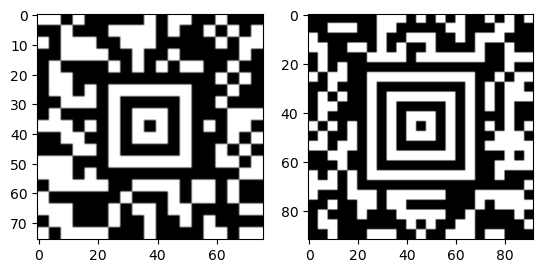

1


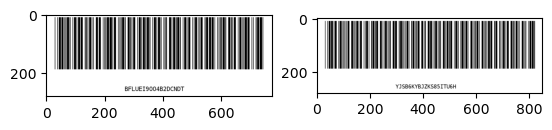

2


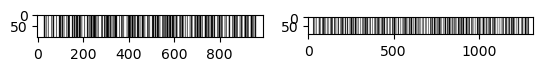

3


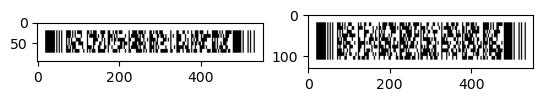

4


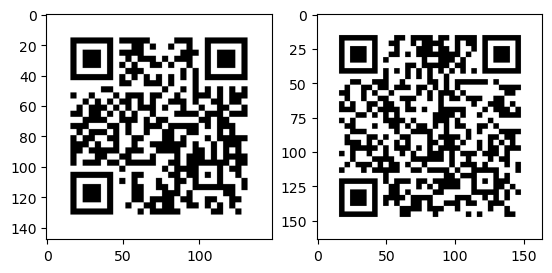

5


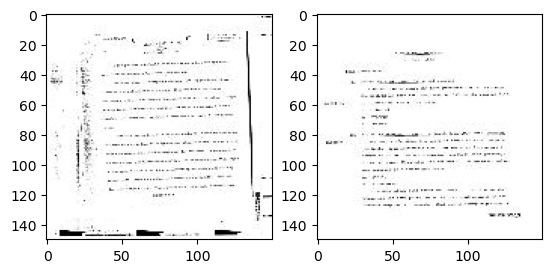

In [12]:
for label in sorted(list(set(y))):
    print(label)
    plt.subplot(121)
    plt.imshow(X_imgs[y == label][0], cmap='gray')
    plt.subplot(122)
    plt.imshow(X_imgs[y == label][100], cmap='gray')
    plt.show()

## Let us try simpliest feature -- ratio of white color on the image.

In [531]:
def get_features(X_imgs, y):
    X = []
    Y = []
    for img, yy in tqdm(zip(X_imgs, y), desc='Extracting features...', total=len(X_imgs)):
        # for rot in range(4):
        #     if rot != 4:
        #         im = cv2.rotate(img, rot)
        #     else:
        #         im = img
        im = img
        X.append([
            (im.astype(float) / 255).sum() / im.size,
            (im[1:] - im[:-1]).sum() / im.size,
            (im[:,1:] - im[:,:-1]).sum() / im.size,
            im.shape[0] / im.shape[1],
        ])
        Y.append(yy)
    X = np.array(X)
    Y = np.array(Y)
    return X, Y

In [533]:
from sklearn.model_selection import train_test_split

In [535]:
X, Y = get_features(X_imgs, y)

Extracting features...: 100%|███████████████████████████████████████████████████████| 7000/7000 [00:08<00:00, 835.38it/s]


In [536]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, random_state=42)

In [537]:
from sklearn.linear_model import LogisticRegression as LR

### Only training part of the dataset is labeled. So, it is the only part of the dataset we can use for training and testing.
### Let us try test on the same part we used for training (not a good idea, actually):

In [539]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [540]:
# Here we are training Logistic Regression:
scaler = StandardScaler()
lr = LR()
model = Pipeline([('scaler', scaler), ('LR', lr)])

model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('LR', LogisticRegression())])

#### Calculating the score:

(array([1247., 1926.,  453.,  246.,  128.,    0.,    0.,    0.,    0.,
        3000.]),
 array([0.05509642, 0.14958678, 0.24407713, 0.33856749, 0.43305785,
        0.52754821, 0.62203857, 0.71652893, 0.81101928, 0.90550964,
        1.        ]),
 <BarContainer object of 10 artists>)

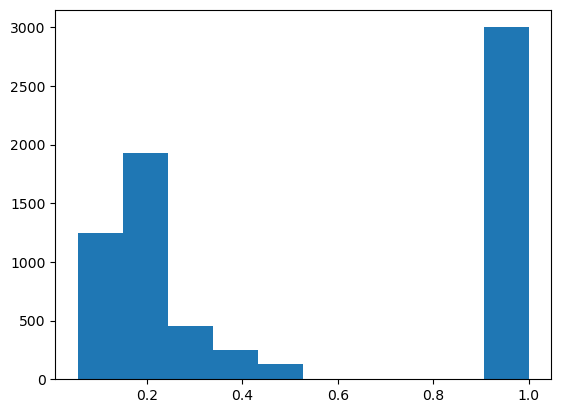

In [542]:
plt.hist(X[:,-1])

In [543]:
model.score(X_test, y_test)

0.9994285714285714

#### Score above is accuracy score. We may calculate it manually by calculating ratio of correct classifications:

In [545]:
y_pred = model.predict(X_test)
print('Accuracy =', (y_pred == y_test).sum() / len(y_test))

Accuracy = 0.9994285714285714


## Let us review testing data and generate resulting file:

In [548]:
X_test_imgs = []
test_names = []
for fn in tqdm(glob('data/barcodes/test/*'), desc='Reading test set'):
    X_test_imgs.append(cv2.imread(fn, cv2.IMREAD_GRAYSCALE))
    test_names.append(os.path.basename(fn))
X_test_imgs = np.array(X_test_imgs, dtype="object")

Reading test set: 100%|█████████████████████████████████████████████████████████████| 1750/1750 [00:02<00:00, 674.08it/s]


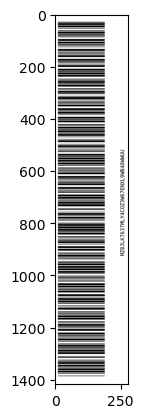

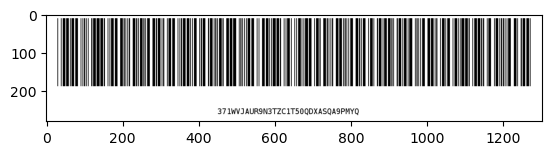

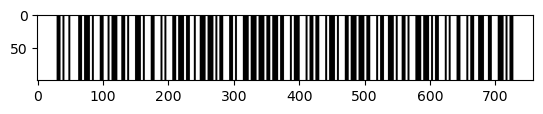

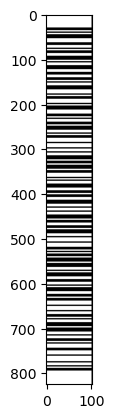

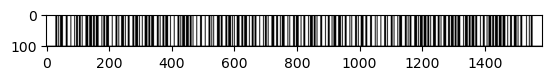

In [549]:
for im in X_test_imgs[:5]:
    plt.imshow(im, cmap='gray')
    plt.show()

## As you may see, images in the dataset can be rotated. You should be able to deal with it.

## Let us generate the answer:

In [552]:
X_test, Y_test = get_features(X_test_imgs, y_test)

Extracting features...: 100%|███████████████████████████████████████████████████████| 1750/1750 [00:02<00:00, 865.73it/s]


In [554]:
y_test_pred = model.predict(X_test)

0


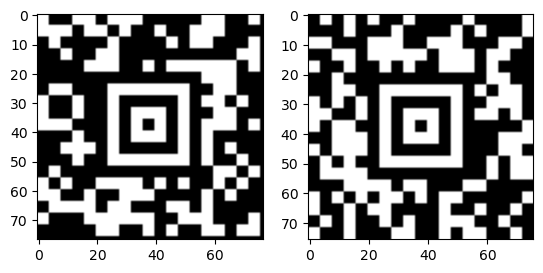

1


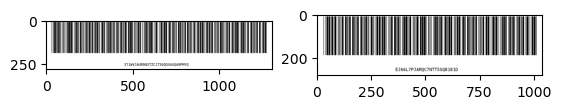

2


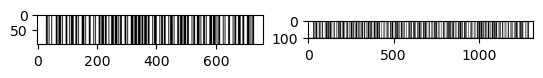

3


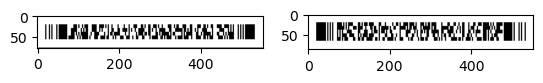

4


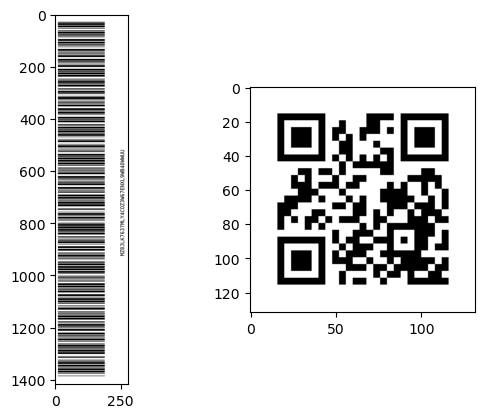

5


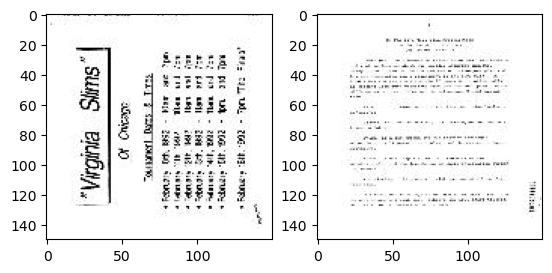

In [563]:
for label in sorted(list(set(y))):
    print(label)
    if (y_test_pred == label).sum() < 6:
        continue
    plt.subplot(121)
    plt.imshow(X_test_imgs[y_test_pred == label][0], cmap='gray')
    plt.subplot(122)
    plt.imshow(X_test_imgs[y_test_pred == label][5], cmap='gray')
    plt.show() 

# Your task is to:
- Find better way to evaluate your model (not to make testing on training set).
- Get higher accuracy (>95% -- 1 point, >97% -- 2 points, >98% -- 3 points, >99% -- 4 points, >99.5% -- 5 pointis).
- Plot confusion matrix for your model (1 point) and ROC curves for each class (1 point).

In [565]:
# store matrix and ROC curves as images here:
conf_matrix = None
ROC_curves = []

In [566]:
answer_to_submit = {fn: yy for fn, yy in zip(test_names, y_test_pred)}

In [567]:
with open('my_answer.pkl', 'wb') as f:
    pkl.dump((answer_to_submit, conf_matrix, ROC_curves, uuid.uuid4().hex, time()), f)

### Now submit `my_answer.pkl` (either to google classroom or to yandex contest, I will let you know the proper way after the weekend).

In [449]:
rotated = {fn: im.shape[0]/im.shape[1] > 1 for im, fn in zip(X_test_imgs, test_names)}

In [360]:
import pandas as pd

In [362]:
d = pd.read_csv(r"D:\Data\miptqrcodesclf\test_labels.csv")

In [451]:
dd = {fn.replace('.jpg', '.png'): (label, rotated[fn.replace('.jpg', '.png')]) for fn, label in zip(d.iloc[:,0].values, d.iloc[:,1].values)}

In [453]:
with open('test_data.pkl', 'wb') as f:
    pkl.dump(dd, f)